# 05 Ranges for the planner, and the forecast from the newest data

A single number, such as "2,178 applications in November", hides how uncertain it is. A planner cannot work with that alone. SEM has to decide how much capacity to keep ready, and having too few places is worse than having a few too many, because it forces early transfers to the cantons. So what a planner really needs is a **range**, and above all an **upper bound**: a number that the actual applications will rarely exceed.

In the present notebook, we add simple 80% and 90% ranges to the forecasts of our chosen model, the linear regression. Then we check how often the actual number really falls inside them, in the backtest and in the test period. Finally, we give the forecast a planner would get today, from the newest data (origin September 2026).

To do this, we read the cleaned series (`../data/processed/asylum_clean.csv`), the backtest forecasts of the regressions from `02b` (`../data/processed/backtest_forecasts_regression.csv`) and the test forecasts from `04` (`../data/processed/test_forecasts.csv`). We save how often the ranges contain the actual numbers (`../output/tables/05_range_coverage.csv`), the forecast from September 2026 (`../output/tables/05_forecast_from_2026_09.csv`) and one figure in `../output/figures/`.

This notebook was added later, after the test run. It only uses forecasts the chosen model had already made, so it changes nothing in the choice or in the test result.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. How the ranges are built

The idea is to let the model's own history tell us how wrong it tends to be. At an origin $t$ and horizon $h$, we take the errors in logs, $\log y - \log \hat y$, of all **earlier** forecasts of the same horizon whose month is already known at $t$. We use errors in logs because they are relative: being 300 off means a lot in a month with 1,000 applications and little in one with 5,000.

The 80% range then goes from the forecast times $e^{q_{10}}$ to the forecast times $e^{q_{90}}$, where $q_{10}$ and $q_{90}$ are the 10th and 90th percentiles of these past errors. For the 90% range we use $q_5$ and $q_{95}$. In words: if the model was 20% too low in the worst tenth of past months, the upper bound of the 80% range is 20% above the forecast.

We need at least 24 past errors before we build a range, because with fewer the 10th and 90th percentiles would rest on just one or two months. So the first ranges are for 2015.

Each range uses only errors known at its origin, never later ones. So checking how often the actual number falls inside is an honest check, just like the backtest itself: a planner could have built exactly these ranges at the time.

*Not seen in class:* `Series.quantile(0.1)` gives the 10th percentile.

In [2]:
MIN_PAST = 24
LEVELS = {"80%": (0.10, 0.90), "90%": (0.05, 0.95)}
TEST_START = pd.Timestamp("2024-10-01")

def read(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    data["origin"] = pd.to_datetime(data["origin"])
    return data

backtest = read("../data/processed/backtest_forecasts_regression.csv")
test = read("../data/processed/test_forecasts.csv")
fc = pd.concat([backtest[backtest["model"] == "Linear regression"], test[test["model"] == "Linear regression"]], ignore_index=True)
fc = fc[["origin", "month", "h", "forecast_log", "actual_log", "forecast", "actual"]].sort_values(["h", "origin"]).reset_index(drop=True)
fc["log_error"] = fc["actual_log"] - fc["forecast_log"]

rows = []
for h, g in fc.groupby("h"):
    for _, r in g.iterrows():
        past = g.loc[g["month"] <= r["origin"], "log_error"]        # errors already known at the origin
        if len(past) < MIN_PAST:
            continue
        out = {"h": h, "origin": r["origin"], "month": r["month"], "forecast": r["forecast"], "actual": r["actual"]}
        for level, (lo, hi) in LEVELS.items():
            out[f"low {level}"] = r["forecast"] * np.exp(past.quantile(lo))
            out[f"high {level}"] = r["forecast"] * np.exp(past.quantile(hi))
        rows.append(out)
ranges = pd.DataFrame(rows)
ranges["period"] = np.where(ranges["month"] >= TEST_START, "test", "backtest")
for level in LEVELS:
    ranges[f"inside {level}"] = (ranges["actual"] >= ranges[f"low {level}"]) & (ranges["actual"] <= ranges[f"high {level}"])
    ranges[f"above {level}"] = ranges["actual"] > ranges[f"high {level}"]
    ranges[f"width {level}"] = ranges[f"high {level}"] - ranges[f"low {level}"]
print("First month with a range:", ranges["month"].min().strftime("%Y-%m"), "| ranges:", len(ranges))

First month with a range: 2015-01 | ranges: 414


## 2. How often is the actual number inside the range?

A range is only useful if it keeps its promise. An 80% range should contain about 80% of the actual numbers: if it contains much fewer, the planner is surprised too often; if it contains almost all, it is wider than needed and wastes capacity. Because the planner cares most about the upper bound, we also check how often the actual number lies above the upper bound of the 90% range: that should happen in about 5% of the months. We also look at how wide the ranges are, in applications and in percent of the forecast, because a range that is always right but very wide does not help much.

In [3]:
coverage = ranges.groupby(["h", "period"]).agg(
    months=("actual", "size"),
    inside_80=("inside 80%", "mean"), inside_90=("inside 90%", "mean"),
    above_upper_90=("above 90%", "mean"),
    width_80=("width 80%", "mean"), forecast=("forecast", "mean"))
coverage["width_80_in_%_of_forecast"] = 100 * coverage["width_80"] / coverage["forecast"]
coverage = coverage.round({"inside_80": 2, "inside_90": 2, "above_upper_90": 2, "width_80": 0, "forecast": 0,
                           "width_80_in_%_of_forecast": 0})
coverage.to_csv("../output/tables/05_range_coverage.csv")
coverage

months  inside_80  inside_90  above_upper_90  width_80  forecast  \
h period                                                                       
1 backtest     117       0.81       0.90            0.04     781.0    1841.0   
  test          24       0.96       0.96            0.00     740.0    2027.0   
2 backtest     115       0.80       0.89            0.07    1172.0    1826.0   
  test          23       1.00       1.00            0.00    1139.0    2026.0   
3 backtest     113       0.80       0.88            0.06    1507.0    1825.0   
  test          22       1.00       1.00            0.00    1481.0    2034.0   

            width_80_in_%_of_forecast  
h period                               
1 backtest                       42.0  
  test                           37.0  
2 backtest                       64.0  
  test                           56.0  
3 backtest                       83.0  
  test                           73.0

An average over all years could hide that the ranges fail exactly when they matter most, in a crisis. So we repeat the check at $h = 2$ period by period, with the crisis periods of `03` shown apart.

In [4]:
h2 = ranges[ranges["h"] == 2].copy()
h2["part"] = np.where(h2["month"] < pd.Timestamp("2015-07-01"), "2015-01 to 2015-06",
             np.where(h2["month"] < pd.Timestamp("2017-01-01"), "2015-07 to 2016-12 (crisis)",
             np.where(h2["month"] < pd.Timestamp("2020-01-01"), "2017 to 2019",
             np.where(h2["month"] < TEST_START, "2020-01 to 2024-09", "test 2024-10 to 2026-09"))))
h2.groupby("part").agg(months=("actual", "size"), inside_80=("inside 80%", "mean"),
                       above_upper_80=("above 80%", "mean"), width_80=("width 80%", "mean")).round(2)

,months,inside_80,above_upper_80,width_80
part,,,,
2015-01 to 2015-06,4,0.50,0.50,662.59
2015-07 to 2016-12 (crisis),18,0.72,0.06,2463.43
2017 to 2019,36,0.89,0.11,801.16
2020-01 to 2024-09,57,0.79,0.12,1034.12
test 2024-10 to 2026-09,23,1.00,0.00,1138.73


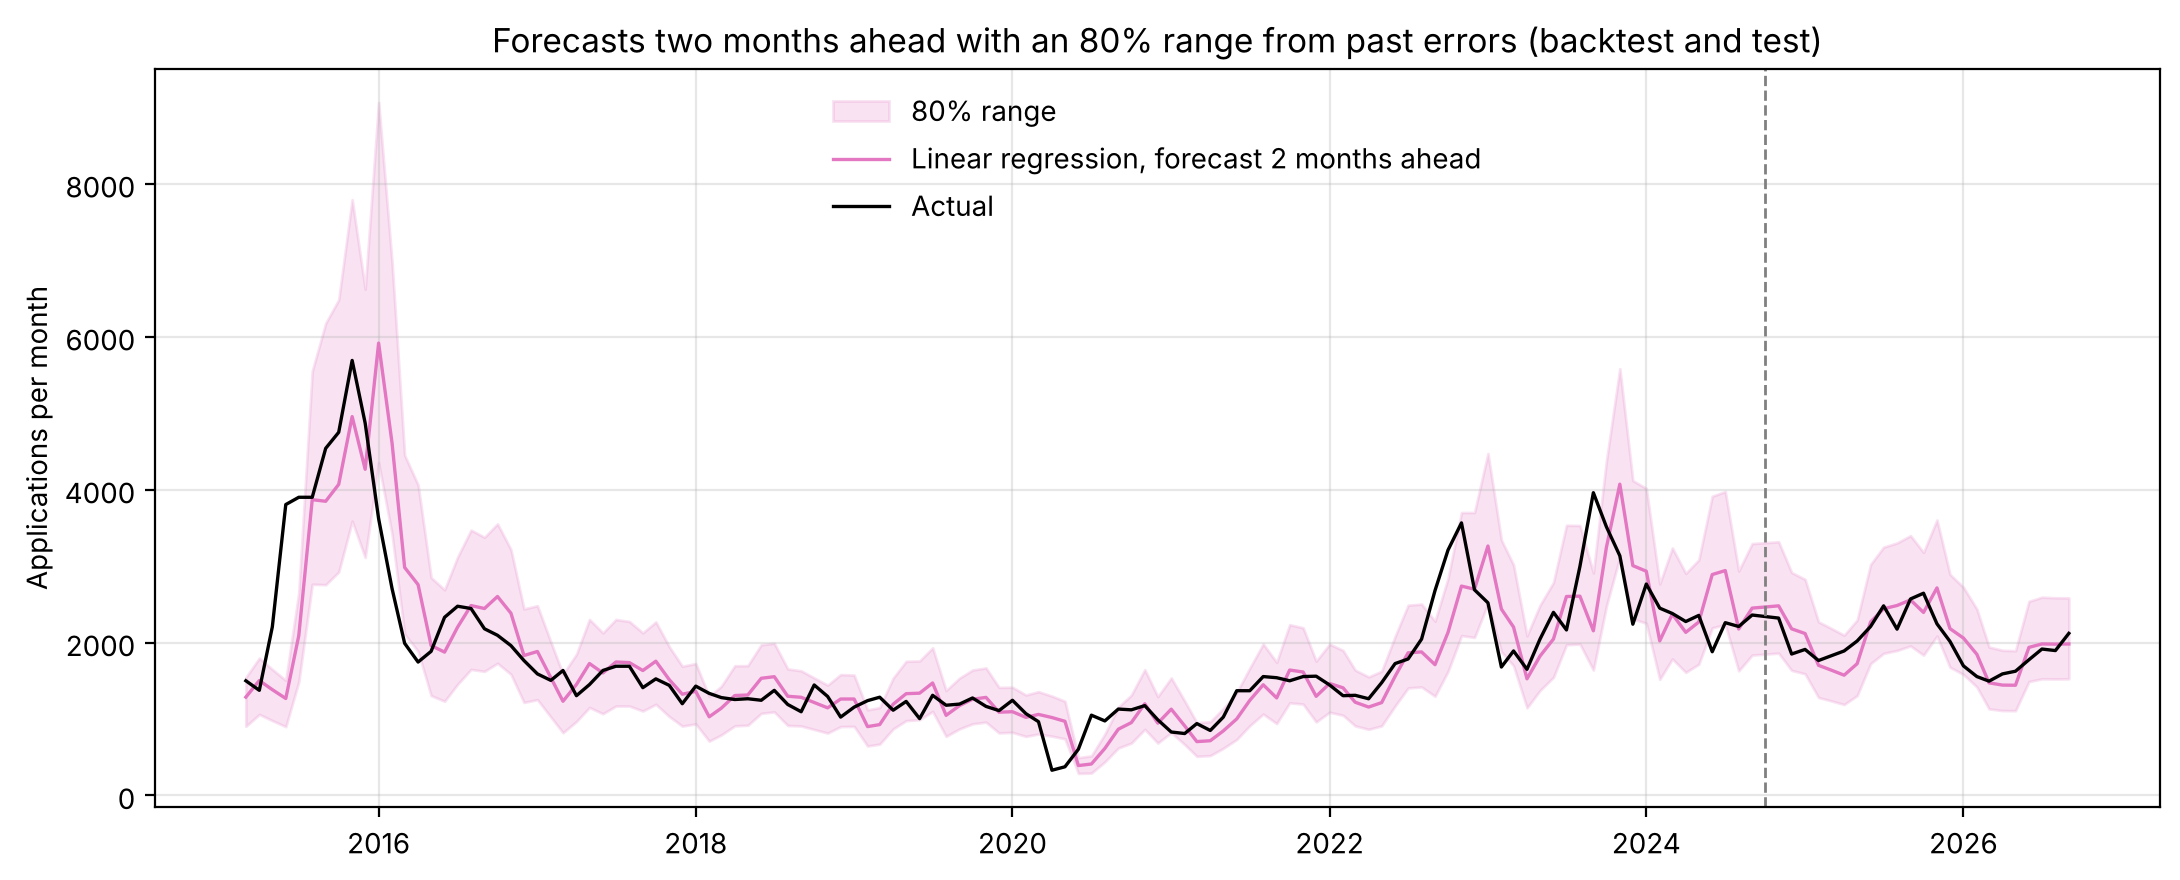

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(h2["month"], h2["low 80%"], h2["high 80%"], color=plt.cm.tab10(6), alpha=0.2, label="80% range")
ax.plot(h2["month"], h2["forecast"], color=plt.cm.tab10(6), linewidth=1.2, label="Linear regression, forecast 2 months ahead")
ax.plot(h2["month"], h2["actual"], color="black", linewidth=1.2, label="Actual")
ax.axvline(TEST_START, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Applications per month")
ax.set_title("Forecasts two months ahead with an 80% range from past errors (backtest and test)")
ax.legend(loc="upper center", frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/05_ranges_h2.png")
plt.show()

As we can see, in the backtest the ranges do what they promise. The 80% range contains 80% to 81% of the actual numbers at every horizon, and the 90% range 88% to 90%. The actual number is above the upper bound of the 90% range in 4% to 7% of the months, close to the 5% expected.

But the ranges are wide. At $h = 2$, the 80% range is on average 1,172 applications wide, 64% of the forecast, so roughly ±30% around it. They widen with the horizon, from 42% of the forecast at $h = 1$ to 83% at $h = 3$, because errors grow the further ahead we forecast.

The average hides two problems, both due to the same cause: the ranges learn only from **past** errors, so they react late. In the calm test period they are too wide: at $h = 2$ and $h = 3$ they contain every actual number, because the past errors they are built on still include the 2015–16 crisis. That 23 of 23 months fall inside is therefore not a proof that the ranges are well calibrated, only that the period was calm. In a crisis they are too narrow: in the first half of 2015, only 2 of 4 months are inside, because the past errors came from calm years, and from July 2015 to 2016, 72%. In the figure, the band widens only after the big misses. In the calmer years in between, they do better (89% inside in 2017 to 2019, 79% from 2020 to September 2024).

So the ranges are honest on average over the backtest and easy to explain, but they react late: too narrow at the start of a crisis, too wide after one. For SEM, they can inform monthly intake planning in normal times, for example by preparing for the upper end. They cannot warn of a new crisis, and decisions on beds also need data on occupancy and on how long people stay.

## 3. The forecast from the newest data

This is what all the work is for: what a planner would get from our model today. We use the newest data, up to September 2026, fit the linear regression of `02b` on all months known at that origin, and add the ranges built from all past errors. The function `make_table` is copied from `04_test.ipynb`, so the model is exactly the one we tested.

One honest caveat: these forecasts were made after SEM had published the number for October (mid-November). So **October is not a live test**, even though the model did not use it. A real live test would have needed the forecast saved before SEM's release. Our plan had foreseen one, but we did not lock it in time.

In [6]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")
y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index
last = len(months) - 1

def make_table(h):
    # Copied from 04_test (rows up to the last month; the newest rows have no target yet)
    rows = []
    for t in range(12, len(log_y)):
        forecast_month = months[t] + pd.DateOffset(months=h)
        rows.append({
            "t": t,
            "change_last_month": log_y[t] - log_y[t - 1],
            "change_month_before": log_y[t - 1] - log_y[t - 2],
            "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
            "calendar_month": forecast_month.month,
            "target": log_y[t + h] - log_y[t] if t + h <= last else np.nan,
        })
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month").astype(float).drop(columns="month_1")
    X = pd.concat([table[["change_last_month", "change_month_before", "same_change_last_year"]], dummies], axis=1)
    return X, table["target"]

rows = []
for h in [1, 2, 3]:
    X, target = make_table(h)
    train_rows = [t for t in X.index if t + h <= last]
    model = make_pipeline(StandardScaler(), LinearRegression()).fit(X.loc[train_rows], target.loc[train_rows])
    forecast = np.exp(log_y[last] + model.predict(X.loc[[last]])[0])
    past = fc.loc[(fc["h"] == h) & (fc["month"] <= months[last]), "log_error"]
    rows.append({"month": (months[last] + pd.DateOffset(months=h)).strftime("%Y-%m"), "h": h, "forecast": round(forecast),
                 "low 80%": round(forecast * np.exp(past.quantile(0.10))), "high 80%": round(forecast * np.exp(past.quantile(0.90))),
                 "high 90% (plan for)": round(forecast * np.exp(past.quantile(0.95)))})
newest = pd.DataFrame(rows).set_index("month")
newest.to_csv("../output/tables/05_forecast_from_2026_09.csv")
print("Origin:", months[last].strftime("%Y-%m"), "(last known month)")
newest

Origin: 2026-09 (last known month)


,h,forecast,low 80%,high 80%,high 90% (plan for)
month,,,,,
2026-10,1,2226,1873,2669,3061
2026-11,2,2178,1678,2839,3361
2026-12,3,1854,1350,2599,3146


Using the data up to September 2026, the model expects 2,226 applications in October 2026 (80% range 1,873 to 2,669), 2,178 in November (1,678 to 2,839) and 1,854 in December (1,350 to 2,599). This is the usual fall towards the end of the year. The upper bounds of the 90% range are about 3,061, 3,361 and 3,146. In the backtest, the actual number was above that level in only 4% to 7% of the months, so these are reasonable numbers to prepare for in normal times, but not in a new crisis.

## Summary

In this notebook, we built ranges from the model's own past errors. The 80% range goes from the 10th to the 90th percentile of the earlier forecast errors in logs, the 90% range from the 5th to the 95th, always using only errors known at each origin. They are simple to build and to explain.

In the backtest, the ranges keep their promise on average: the 80% range contains 80% to 81% of the actual numbers and the 90% range 88% to 90%. At $h = 2$ the 80% range is about ±30% of the forecast. But because they learn only from the past, they react late: they are too wide in the calm test period (96% to 100% inside) and too narrow at the start of the 2015–16 crisis (72%).

From the data up to September 2026, the model forecasts 2,226 applications for October (80% range 1,873 to 2,669), 2,178 for November and 1,854 for December. This is not a live test, because SEM had already published October when these forecasts were made.

For SEM, the ranges can inform monthly intake planning in normal times. They cannot foresee a crisis, and bed decisions also need occupancy data.

*Not seen in class (marked above):* `Series.quantile`.